First five rows:
  artist_name                track_id  \
0          YG  2RM4jf1Xa9zPgMGRDiht8O   
1          YG  1tHDG53xJNGsItRA3vfVgs   
2       R3HAB  6Wosx2euFPMT14UXiWudMy   
3  Chris Cooq  3J2Jpw61sO7l6Hc7qdYV91   
4  Chris Cooq  2jbYvQCyPgX3CdmAzeVeuS   

                                       track_name  acousticness  danceability  \
0  Big Bank feat. 2 Chainz, Big Sean, Nicki Minaj      0.005820         0.743   
1                    BAND DRUM (feat. A$AP Rocky)      0.024400         0.846   
2                                   Radio Silence      0.025000         0.603   
3                                         Lactose      0.029400         0.800   
4                             Same - Original mix      0.000035         0.783   

   duration_ms  energy  instrumentalness  key  liveness  loudness  mode  \
0       238373   0.339             0.000    1    0.0812    -7.678     1   
1       214800   0.557             0.000    8    0.2860    -7.259     1   
2       138913   0.723  

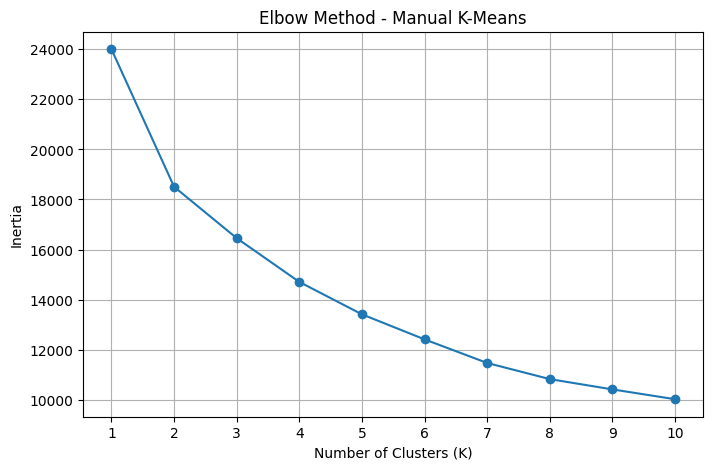


Selected K: 4
Final inertia: 14735.78

First ten clustered songs:
        danceability  energy  acousticness  instrumentalness  liveness  \
48467          0.151  0.0266       0.91600          0.704000    0.0946   
80470          0.534  0.0810       0.97700          0.898000    0.1790   
27028          0.860  0.4530       0.00138          0.004200    0.1000   
7095           0.551  0.6830       0.04880          0.000225    0.0583   
130566         0.606  0.1030       0.05610          0.874000    0.1030   
21004          0.711  0.3740       0.57100          0.000286    0.1510   
8745           0.358  0.2080       0.95900          0.000004    0.2640   
110478         0.569  0.5460       0.11400          0.006400    0.2780   
41431          0.371  0.9750       0.04210          0.000000    0.2140   
2104           0.726  0.6420       0.01350          0.000000    0.1380   

        speechiness  valence    tempo  Cluster  
48467        0.0463   0.0366  136.125        3  
80470        0.0387 

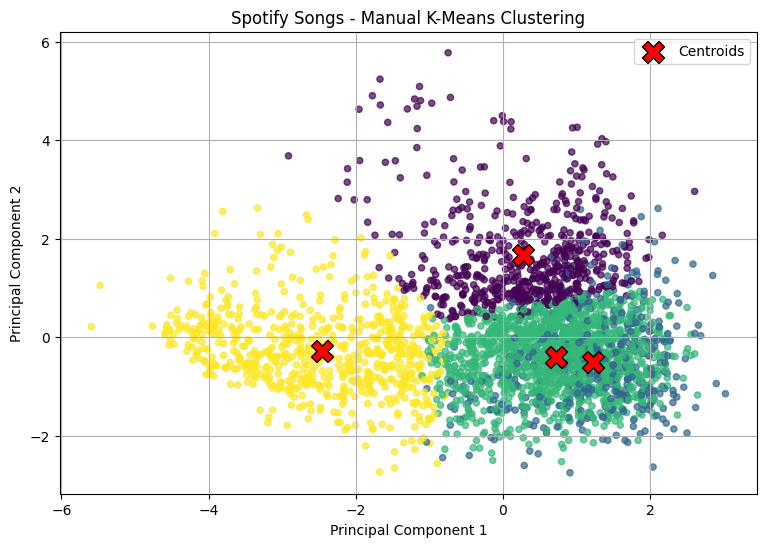


Silhouette Score: 0.189


In [ ]:

# EXPERIMENT: MANUAL K-MEANS CLUSTERING ON SPOTIFY SONGS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# --------------------------------------------------
# 1. LOAD THE KAGGLE DATASET
# --------------------------------------------------

df = pd.read_csv("SpotifyAudioFeaturesApril2019.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())


# --------------------------------------------------
# 2. SELECT AUDIO FEATURES
# --------------------------------------------------

features = [
    "danceability",
    "energy",
    "acousticness",
    "instrumentalness",
    "liveness",
    "speechiness",
    "valence",
    "tempo"
]

missing_columns = [col for col in features if col not in df.columns]

if missing_columns:
    raise ValueError(
        "Missing feature columns: " + str(missing_columns)
        + ". Check the actual CSV column names."
    )

X = df[features].copy()

# Convert features to numeric values
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

# Use a sample for faster execution
if len(X) > 3000:
    X = X.sample(n=3000, random_state=42)

print("\nNumber of songs used:", len(X))


# --------------------------------------------------
# 3. FEATURE SCALING
# --------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --------------------------------------------------
# 4. MANUAL K-MEANS ALGORITHM
# --------------------------------------------------

def manual_kmeans(X, k, max_iters=100, tol=1e-4,
                  n_init=3, random_state=42):

    rng = np.random.default_rng(random_state)
    best_inertia = float("inf")
    best_labels = None
    best_centroids = None

    # Try different initial centroids
    for run in range(n_init):

        # Step 1: Randomly choose k data points as centroids
        indices = rng.choice(len(X), size=k, replace=False)
        centroids = X[indices].copy()

        for iteration in range(max_iters):

            # Step 2: Calculate squared distance
            # between each point and each centroid
            distances = np.sum(
                (X[:, np.newaxis, :] -
                 centroids[np.newaxis, :, :]) ** 2,
                axis=2
            )

            # Step 3: Assign each point to nearest centroid
            labels = np.argmin(distances, axis=1)

            # Step 4: Calculate new centroids using means
            new_centroids = np.zeros_like(centroids)

            for j in range(k):
                cluster_points = X[labels == j]

                if len(cluster_points) > 0:
                    new_centroids[j] = np.mean(
                        cluster_points, axis=0
                    )
                else:
                    # Reinitialize an empty cluster
                    new_centroids[j] = X[
                        rng.integers(len(X))
                    ]

            # Step 5: Check centroid movement
            movement = np.linalg.norm(
                new_centroids - centroids
            )

            centroids = new_centroids

            if movement < tol:
                break

        # Calculate final inertia for this run
        final_distances = np.sum(
            (X - centroids[labels]) ** 2,
            axis=1
        )

        inertia = np.sum(final_distances)

        # Keep the best initialization
        if inertia < best_inertia:
            best_inertia = inertia
            best_labels = labels.copy()
            best_centroids = centroids.copy()

    return best_labels, best_centroids, best_inertia


# --------------------------------------------------
# 5. ELBOW METHOD USING MANUAL K-MEANS
# --------------------------------------------------

k_values = range(1, 11)
inertia_values = []

for k in k_values:
    labels, centers, inertia = manual_kmeans(
        X_scaled,
        k,
        random_state=42 + k
    )

    inertia_values.append(inertia)
    print("K =", k, "| Inertia =", round(inertia, 2))

# Plot elbow graph
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method - Manual K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


# --------------------------------------------------
# 6. SELECT K AND TRAIN FINAL MODEL
# --------------------------------------------------

# Example choice. Examine your elbow graph and adjust K.
optimal_k = 4

cluster_labels, centroids_scaled, final_inertia = manual_kmeans(
    X_scaled,
    optimal_k,
    random_state=42
)

print("\nSelected K:", optimal_k)
print("Final inertia:", round(final_inertia, 2))


# --------------------------------------------------
# 7. ADD CLUSTER LABELS TO DATA
# --------------------------------------------------

result = X.copy()
result["Cluster"] = cluster_labels

print("\nFirst ten clustered songs:")
print(result.head(10))

print("\nNumber of songs in each cluster:")
print(result["Cluster"].value_counts().sort_index())


# --------------------------------------------------
# 8. DISPLAY CENTROIDS IN ORIGINAL UNITS
# --------------------------------------------------

centroids = scaler.inverse_transform(centroids_scaled)

centroid_table = pd.DataFrame(
    centroids,
    columns=features
)

print("\nCluster centroids:")
print(centroid_table.round(3))

print("\nAverage audio features by cluster:")
print(result.groupby("Cluster")[features].mean().round(3))


# --------------------------------------------------
# 9. VISUALIZE CLUSTERS USING PCA
# --------------------------------------------------

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

centroids_pca = pca.transform(centroids_scaled)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=20,
    alpha=0.7
)

plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c="red",
    marker="X",
    s=250,
    edgecolors="black",
    label="Centroids"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Spotify Songs - Manual K-Means Clustering")
plt.legend()
plt.grid(True)
plt.show()


# --------------------------------------------------
# 10. SILHOUETTE SCORE
# --------------------------------------------------

score = silhouette_score(
    X_scaled,
    cluster_labels,
    sample_size=min(1000, len(X_scaled)),
    random_state=42
)

print("\nSilhouette Score:", round(score, 3))